# Part 1 — Dataset discovery & exploration

**Lab:** In God we trust, everyone else bring the data · **Analyst:** Elif Yurdakul

## Step 1 — Dataset choice

| | |
|---|---|
| **Name** | Marketing Campaign Performance Dataset |
| **Source** | Kaggle (author: manishabhatt22) |
| **URL** | https://www.kaggle.com/datasets/manishabhatt22/marketing-campaign-performance-dataset |
| **Size** | 200,000 campaigns × 16 columns, 1 Jan – 31 Dec 2021 |
| **Download** | `scripts/download_dataset.py` (kagglehub, token read from `.env`) |

**Why this dataset**
- **Six channels to compare** (`Channel_Used`: Email, Facebook, Google Ads, Instagram, Website, YouTube), with about 33,000 campaigns each. The lab scenario mentions 7 channels; this dataset has 6, so the budget is split across 6.
- **All the funnel metrics needed:** impressions, clicks, conversion rate, cost (`Acquisition_Cost`) and ROI. From them we can derive conversions, revenue, CTR, CPA and ROAS.
- **A daily date column covering a full year.** Aggregated to channel × day, this gives 365 observations per channel for t-tests and power analysis, plus click/conversion counts for Fisher's exact test.

**Known limitation:** the dataset is widely believed to be synthetic. Values look uniformly distributed (for example, ROI spans 2–8 evenly). That matters for interpretation, and is discussed in the memo.

The raw file is not committed (27 MB); run the download script to recreate `data/raw/`.

## Step 2 — Load and explore

In [1]:
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import fisher_exact, false_discovery_control

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

DATA = Path("data")
FIG = Path("figures")
OUT = Path("outputs")
for p in (DATA, FIG, OUT):
    p.mkdir(exist_ok=True)

ALPHA = 0.05

In [2]:
raw = pd.read_csv(DATA / "raw" / "marketing_campaign_dataset.csv")
print("Shape:", raw.shape)
print()
raw.info()
raw.head()

Shape: (200000, 16)

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Campaign_ID       200000 non-null  int64  
 1   Company           200000 non-null  str    
 2   Campaign_Type     200000 non-null  str    
 3   Target_Audience   200000 non-null  str    
 4   Duration          200000 non-null  str    
 5   Channel_Used      200000 non-null  str    
 6   Conversion_Rate   200000 non-null  float64
 7   Acquisition_Cost  200000 non-null  str    
 8   ROI               200000 non-null  float64
 9   Location          200000 non-null  str    
 10  Language          200000 non-null  str    
 11  Clicks            200000 non-null  int64  
 12  Impressions       200000 non-null  int64  
 13  Engagement_Score  200000 non-null  int64  
 14  Customer_Segment  200000 non-null  str    
 15  Date              200000 non-null  str    
dtypes: float64

,Campaign_ID,Company,Campaign_Type,Target_Audience,Duration,Channel_Used,Conversion_Rate,Acquisition_Cost,ROI,Location,Language,Clicks,Impressions,Engagement_Score,Customer_Segment,Date
0,1,Innovate Industries,Email,Men 18-24,30 days,Google Ads,0.0400,"$16,174.00",6.2900,Chicago,Spanish,506,1922,6,Health & Wellness,2021-01-01
1,2,NexGen Systems,Email,Women 35-44,60 days,Google Ads,0.1200,"$11,566.00",5.6100,New York,German,116,7523,7,Fashionistas,2021-01-02
2,3,Alpha Innovations,Influencer,Men 25-34,30 days,YouTube,0.0700,"$10,200.00",7.1800,Los Angeles,French,584,7698,1,Outdoor Adventurers,2021-01-03
3,4,DataTech Solutions,Display,All Ages,60 days,YouTube,0.1100,"$12,724.00",5.5500,Miami,Mandarin,217,1820,7,Health & Wellness,2021-01-04
4,5,NexGen Systems,Email,Men 25-34,15 days,YouTube,0.0500,"$16,452.00",6.5000,Los Angeles,Mandarin,379,4201,3,Health & Wellness,2021-01-05


### Grouping variable and available metrics

In [3]:
print("Channels (grouping variable):")
print(raw["Channel_Used"].value_counts(), "\n")
print("Other categorical columns (not used as the grouping variable):")
for col in ["Campaign_Type", "Location", "Customer_Segment", "Duration", "Language"]:
    print(f"  {col}: {raw[col].nunique()} values")
print("\nDate range:", raw["Date"].min(), "to", raw["Date"].max(), f"({raw['Date'].nunique()} days)")

Channels (grouping variable):
Channel_Used
Email         33599
Google Ads    33438
YouTube       33392
Instagram     33392
Website       33360
Facebook      32819
Name: count, dtype: int64 

Other categorical columns (not used as the grouping variable):
  Campaign_Type: 5 values
  Location: 5 values
  Customer_Segment: 5 values
  Duration: 4 values
  Language: 5 values

Date range: 2021-01-01 to 2021-12-31 (365 days)


### Data quality checks

In [4]:
checks = {
    "Missing values (all columns)": int(raw.isna().sum().sum()),
    "Duplicate Campaign_IDs": int(raw["Campaign_ID"].duplicated().sum()),
    "Fully duplicated rows": int(raw.duplicated().sum()),
    "Acquisition_Cost stored as text ($12,345.00)": raw["Acquisition_Cost"].dtype == object or str(raw["Acquisition_Cost"].dtype) == "str",
    "Conversion_Rate outside 0–1": int((~raw["Conversion_Rate"].between(0, 1)).sum()),
    "Clicks > Impressions": int((raw["Clicks"] > raw["Impressions"]).sum()),
    "Negative ROI": int((raw["ROI"] < 0).sum()),
}
for k, v in checks.items():
    print(f"{k:<48} {v}")

raw[["Conversion_Rate", "ROI", "Clicks", "Impressions", "Engagement_Score"]].describe().T

Missing values (all columns)                     0
Duplicate Campaign_IDs                           0
Fully duplicated rows                            0
Acquisition_Cost stored as text ($12,345.00)     True
Conversion_Rate outside 0–1                      0
Clicks > Impressions                             0
Negative ROI                                     0


,count,mean,std,min,25%,50%,75%,max
Conversion_Rate,"200,000.0000",0.0801,0.0406,0.0100,0.0500,0.0800,0.1200,0.1500
ROI,"200,000.0000",5.0024,1.7345,2.0000,3.5000,5.0100,6.5100,8.0000
Clicks,"200,000.0000",549.7720,260.0191,100.0000,325.0000,550.0000,775.0000,"1,000.0000"
Impressions,"200,000.0000","5,507.3015","2,596.8643","1,000.0000","3,266.0000","5,517.5000","7,753.0000","10,000.0000"
Engagement_Score,"200,000.0000",5.4947,2.8726,1.0000,3.0000,5.0000,8.0000,10.0000


### Prepare the data

Transformations:
1. **`cost`** — parse `Acquisition_Cost` from text (`"$16,174.00"`) to a number. It is treated as the campaign's spend.
2. **`conversions`** = `Clicks × Conversion_Rate`, rounded to whole conversions.
3. **`revenue`** = `cost × (1 + ROI)`, using the standard definition ROI = (revenue − cost) / cost. So ROAS = 1 + ROI.
4. **`date`** — parse to a date.
5. **Aggregate to channel × day**: sum impressions, clicks, conversions, cost and revenue, then compute daily CTR, conversion rate, CPA and ROAS. Each day gives one observation per channel, and the t-tests compare these daily values.

Clicks never exceed impressions, there are no missing values and IDs are unique. No rows are removed.

In [5]:
df = raw.copy()
df["cost"] = df["Acquisition_Cost"].str.replace(r"[$,]", "", regex=True).astype(float)
df["conversions"] = (df["Clicks"] * df["Conversion_Rate"]).round().astype(int)
df["revenue"] = df["cost"] * (1 + df["ROI"])
df["date"] = pd.to_datetime(df["Date"])
df = df.rename(columns={"Channel_Used": "channel", "Clicks": "clicks", "Impressions": "impressions"})

daily = (
    df.groupby(["date", "channel"], as_index=False)
      .agg(campaigns=("Campaign_ID", "count"), impressions=("impressions", "sum"),
           clicks=("clicks", "sum"), conversions=("conversions", "sum"),
           cost=("cost", "sum"), revenue=("revenue", "sum"))
)
daily["ctr"] = daily["clicks"] / daily["impressions"]
daily["conversion_rate"] = daily["conversions"] / daily["clicks"]
daily["cpa"] = daily["cost"] / daily["conversions"]
daily["roas"] = daily["revenue"] / daily["cost"]
daily = daily.replace([np.inf, -np.inf], np.nan)

daily.to_csv(DATA / "marketing_data.csv", index=False)
print("Saved data/marketing_data.csv:", daily.shape)
daily.head()

Saved data/marketing_data.csv: (2190, 12)


,date,channel,campaigns,impressions,clicks,conversions,cost,revenue,ctr,conversion_rate,cpa,roas
0,2021-01-01,Email,120,653591,66425,5259,"1,495,452.0000","8,820,444.4200",0.1016,0.0792,284.3605,5.8982
1,2021-01-01,Facebook,100,507295,53728,4448,"1,242,186.0000","7,962,050.6700",0.1059,0.0828,279.2684,6.4097
2,2021-01-01,Google Ads,82,447126,42632,3449,"1,077,988.0000","6,142,187.3500",0.0953,0.0809,312.5509,5.6978
3,2021-01-01,Instagram,80,448287,40287,2776,"1,003,917.0000","5,971,753.9800",0.0899,0.0689,361.6416,5.9485
4,2021-01-01,Website,90,530477,43226,3787,"1,140,790.0000","6,788,094.4000",0.0815,0.0876,301.2384,5.9503


In [6]:
print("Number of groups (channels):", daily["channel"].nunique())
print("Date range:", daily["date"].min().date(), "to", daily["date"].max().date())
print("\nSample size per channel (days, campaigns):")
print(daily.groupby("channel").agg(days=("date", "nunique"), campaigns=("campaigns", "sum"),
                                     campaigns_per_day=("campaigns", "mean")).round(1))

Number of groups (channels): 6
Date range: 2021-01-01 to 2021-12-31

Sample size per channel (days, campaigns):
            days  campaigns  campaigns_per_day
channel                                       
Email        365      33599            92.1000
Facebook     365      32819            89.9000
Google Ads   365      33438            91.6000
Instagram    365      33392            91.5000
Website      365      33360            91.4000
YouTube      365      33392            91.5000


## Step 3 — Key marketing metrics by channel

In [7]:
summary = df.groupby("channel")[["impressions", "clicks", "conversions", "cost", "revenue"]].sum()
summary["ctr"] = summary["clicks"] / summary["impressions"]
summary["conversion_rate"] = summary["conversions"] / summary["clicks"]
summary["cpa"] = summary["cost"] / summary["conversions"]
summary["roas"] = summary["revenue"] / summary["cost"]
summary["profit"] = summary["revenue"] - summary["cost"]
summary["profit_margin"] = summary["profit"] / summary["revenue"]
summary = summary.replace([np.inf, -np.inf], np.nan)
summary.to_csv(OUT / "channel_summary.csv")
display_table = summary.copy()
for col in ["ctr", "conversion_rate", "profit_margin"]:
    display_table[col] = display_table[col] * 100   # shown as %, otherwise 2 decimals hides all differences
display_table = display_table.rename(columns={"ctr": "ctr_%", "conversion_rate": "conversion_rate_%", "profit_margin": "profit_margin_%"})
display_table.round(2)

,impressions,clicks,conversions,cost,revenue,ctr_%,conversion_rate_%,cpa,roas,profit,profit_margin_%
channel,,,,,,,,,,,
Email,184801107,18493963,1485425,"420,874,104.0000","2,524,644,207.6800",10.0100,8.0300,283.3400,6.0000,"2,103,770,103.6800",83.3300
Facebook,180659428,18037947,1446338,"410,595,258.0000","2,474,540,725.4100",9.9800,8.0200,283.8900,6.0300,"2,063,945,467.4100",83.4100
Google Ads,185006879,18340807,1468717,"418,912,314.0000","2,516,723,624.9800",9.9100,8.0100,285.2200,6.0100,"2,097,811,310.9800",83.3500
Instagram,183738455,18316654,1462938,"417,124,850.0000","2,497,101,378.7000",9.9700,7.9900,285.1300,5.9900,"2,079,976,528.7000",83.3000
Website,183806353,18414628,1477660,"416,593,500.0000","2,504,152,455.5600",10.0200,8.0200,281.9300,6.0100,"2,087,558,955.5600",83.3600
YouTube,183448082,18350407,1463649,"416,778,582.0000","2,501,104,889.9100",10.0000,7.9800,284.7500,6.0000,"2,084,326,307.9100",83.3400


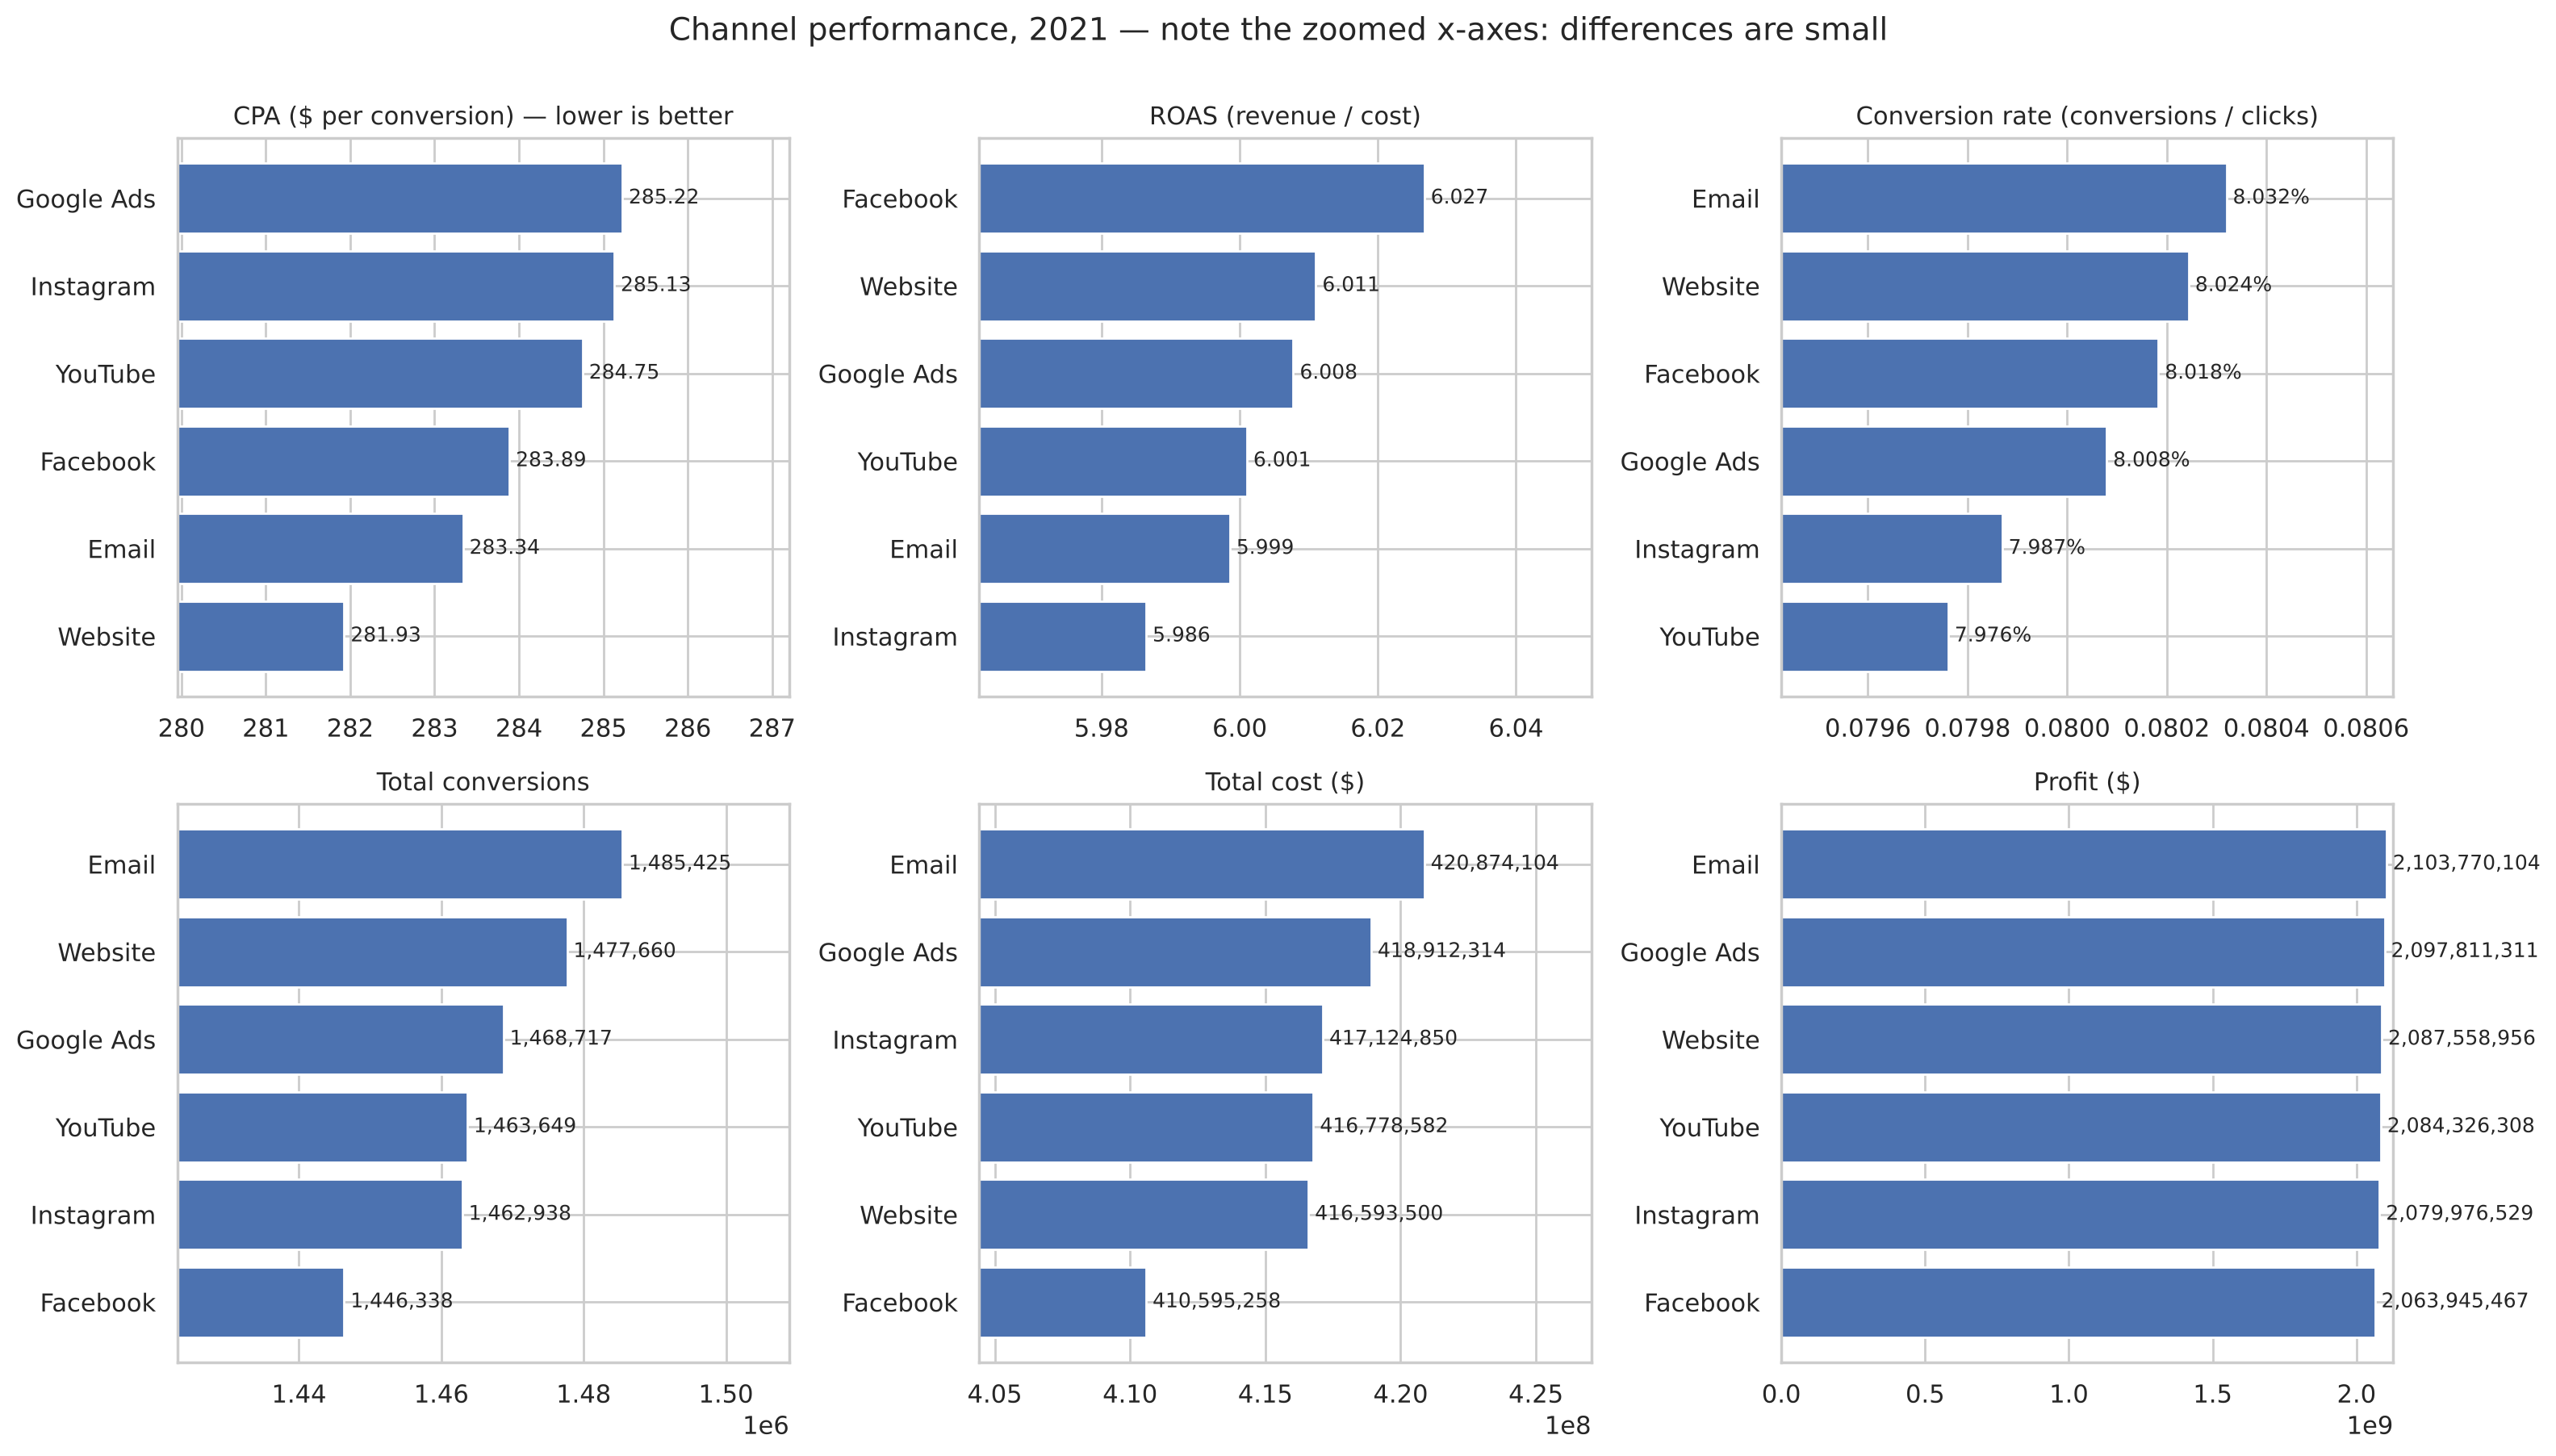

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
plots = [
    ("cpa", "CPA ($ per conversion) — lower is better", "{:,.2f}"),
    ("roas", "ROAS (revenue / cost)", "{:.3f}"),
    ("conversion_rate", "Conversion rate (conversions / clicks)", "{:.3%}"),
    ("conversions", "Total conversions", "{:,.0f}"),
    ("cost", "Total cost ($)", "{:,.0f}"),
    ("profit", "Profit ($)", "{:,.0f}"),
]
for ax, (col, title, fmt) in zip(axes.flat, plots):
    s = summary[col].sort_values()
    ax.barh(s.index, s.values, color="#4C72B0")
    lo, hi = s.min(), s.max()
    pad = (hi - lo) * 0.6 or hi * 0.01
    ax.set_xlim(max(0, lo - pad) if col != "profit" else 0, hi + pad)
    for i, v in enumerate(s.values):
        ax.text(v, i, " " + fmt.format(v), va="center", fontsize=9)
    if col == "profit":
        ax.axvline(0, color="black", lw=1)
    ax.set_title(title, fontsize=11)
fig.suptitle("Channel performance, 2021 — note the zoomed x-axes: differences are small", fontsize=14, y=1.0)
fig.tight_layout()
fig.savefig(FIG / "group_metrics_overview.png", dpi=150, bbox_inches="tight")
plt.show()

The x-axes in the overview are zoomed in so the differences are visible. On an axis starting at zero, all six bars look identical.

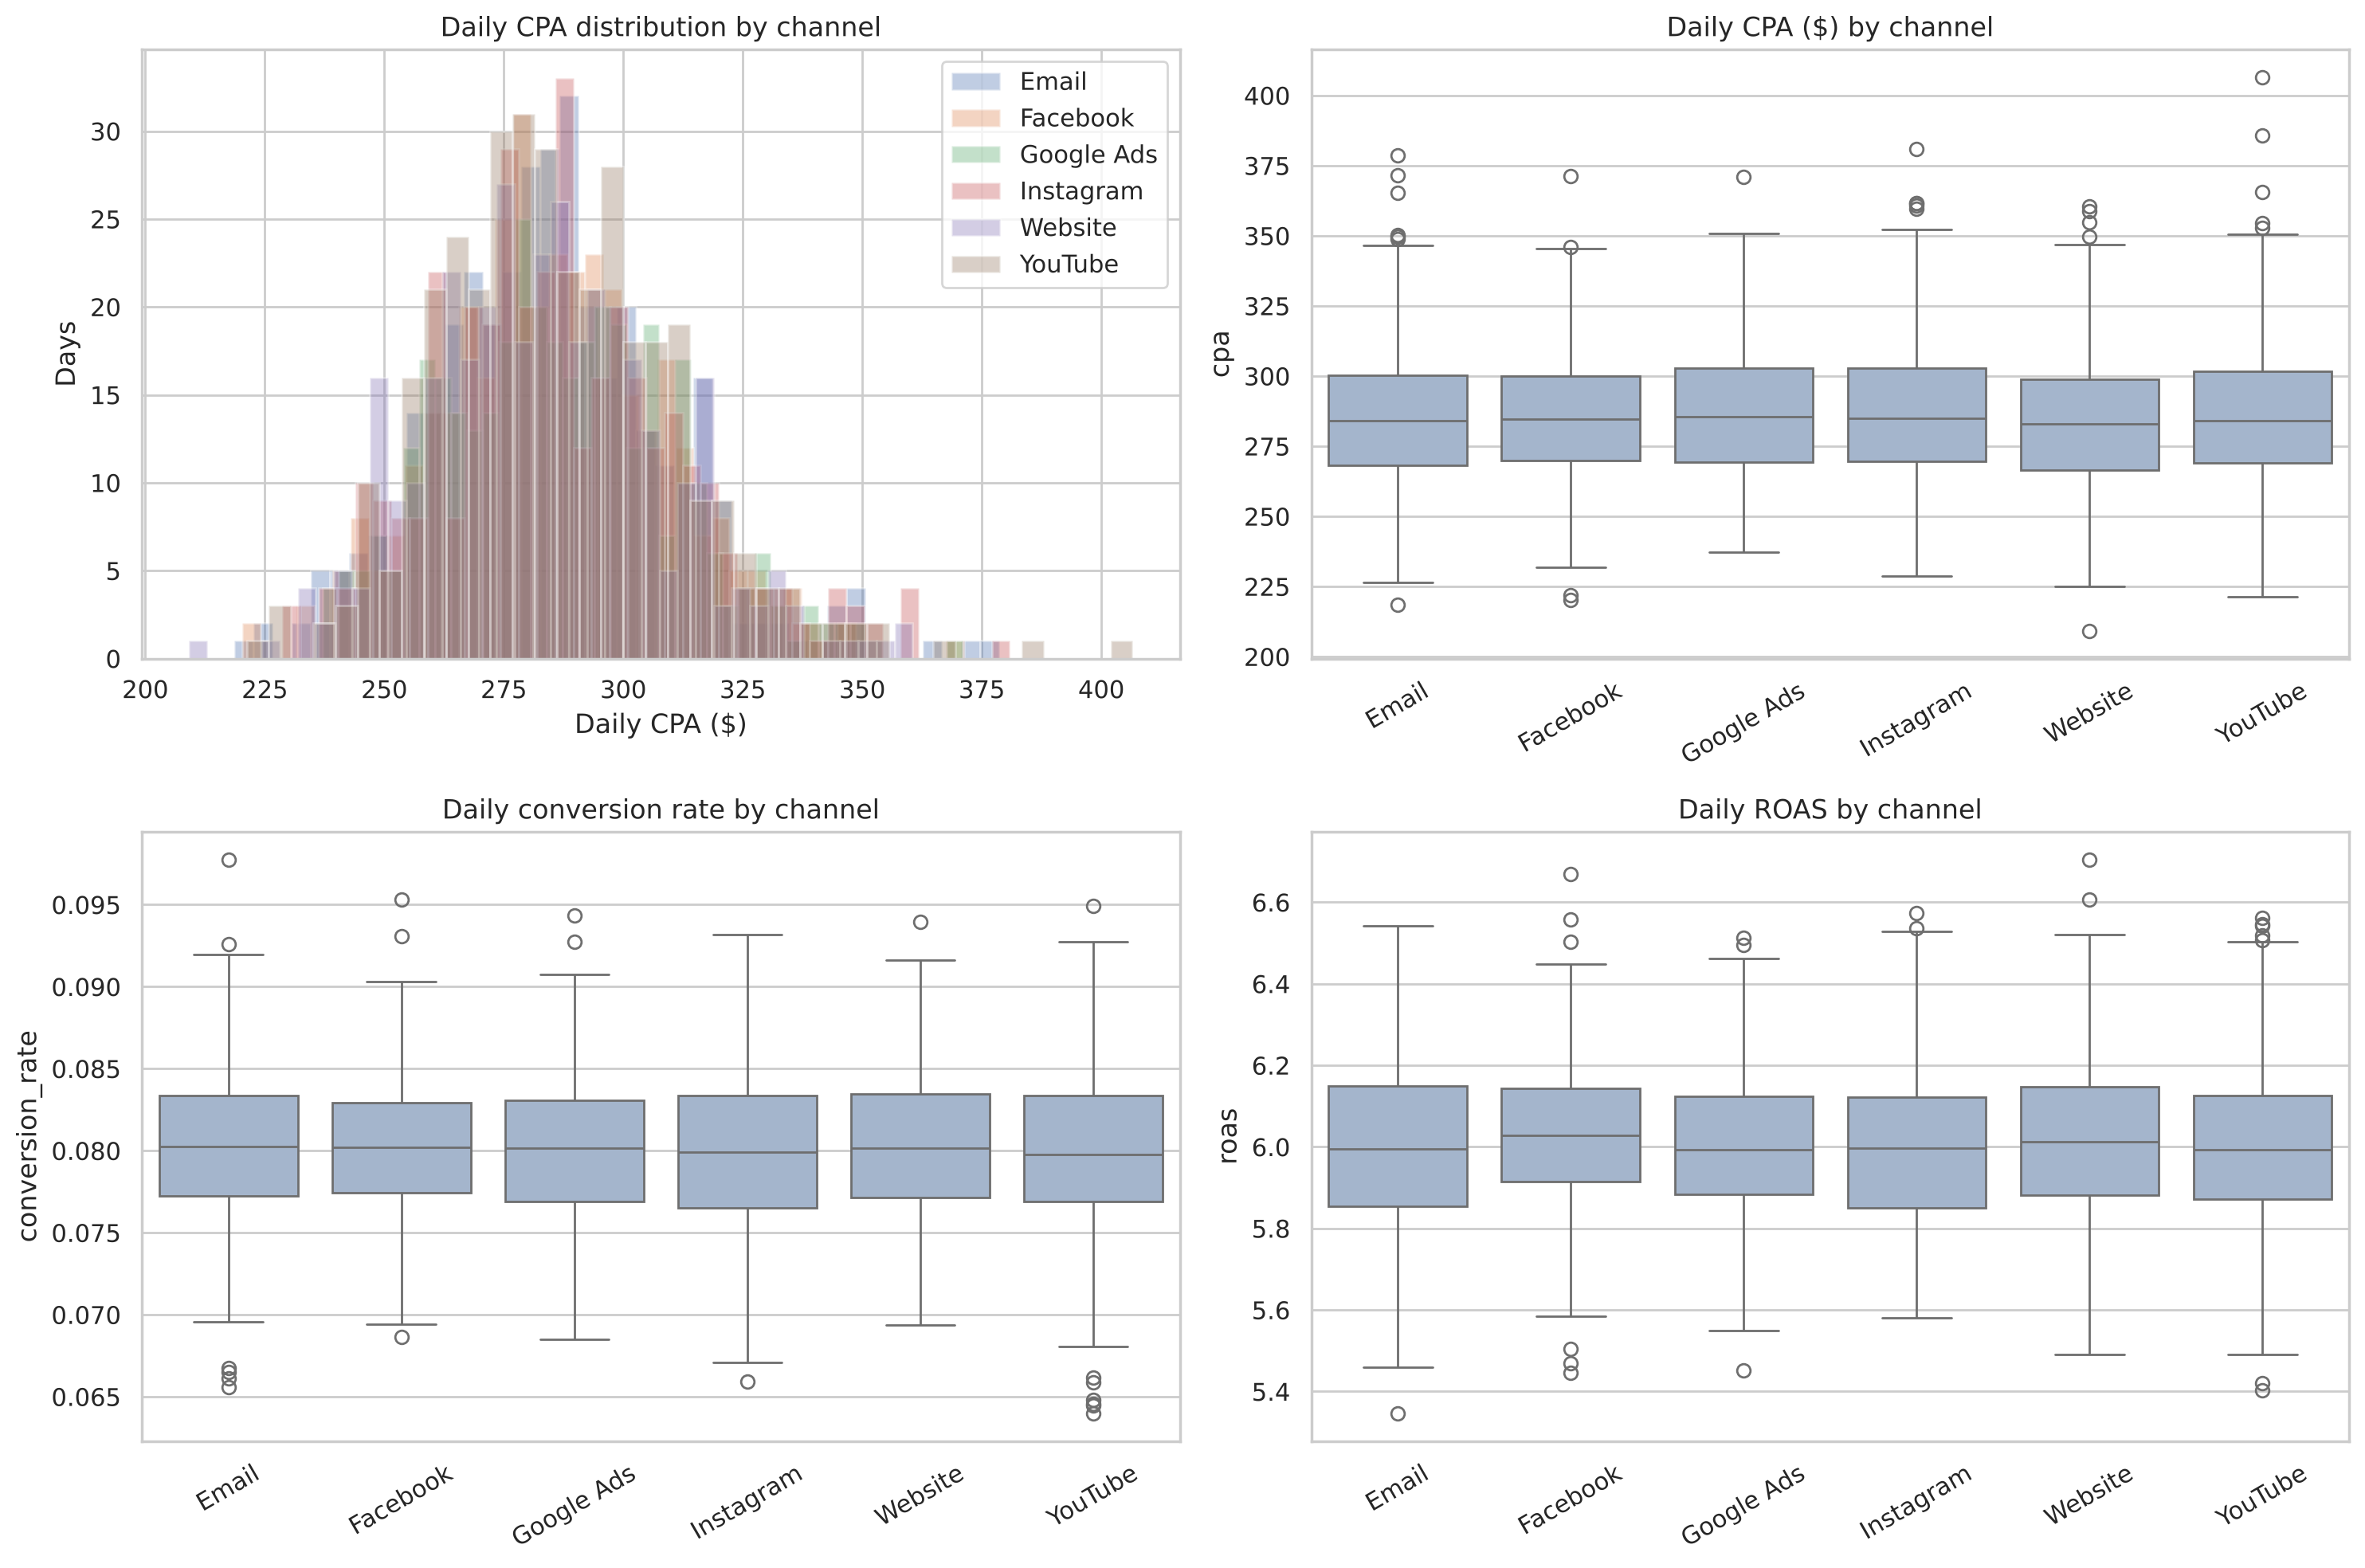

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ch, g in daily.groupby("channel"):
    axes[0, 0].hist(g["cpa"], bins=40, alpha=0.35, label=ch)
axes[0, 0].set(title="Daily CPA distribution by channel", xlabel="Daily CPA ($)", ylabel="Days")
axes[0, 0].legend()

order = sorted(daily["channel"].unique())
for ax, col, title in [(axes[0, 1], "cpa", "Daily CPA ($)"),
                       (axes[1, 0], "conversion_rate", "Daily conversion rate"),
                       (axes[1, 1], "roas", "Daily ROAS")]:
    sns.boxplot(data=daily, x="channel", y=col, order=order, ax=ax, color="#9DB4D3")
    ax.set(title=f"{title} by channel", xlabel="")
    ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(FIG / "group_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
variability = daily.groupby("channel")[["cpa", "conversion_rate", "roas"]].agg(["mean", "std"])
for m in ["cpa", "conversion_rate", "roas"]:
    variability[(m, "cv")] = variability[(m, "std")] / variability[(m, "mean")]
variability = variability.sort_index(axis=1)
print("Daily variability (cv = std / mean):")
variability.round(4)

Daily variability (cv = std / mean):


conversion_rate                  cpa                    roas  \
                        cv   mean    std     cv     mean     std     cv   
channel                                                                   
Email               0.0597 0.0803 0.0048 0.0867 285.0703 24.7036 0.0344   
Facebook            0.0546 0.0802 0.0044 0.0816 285.5653 23.3129 0.0306   
Google Ads          0.0579 0.0801 0.0046 0.0836 286.7996 23.9899 0.0301   
Instagram           0.0616 0.0799 0.0049 0.0907 286.9262 26.0164 0.0315   
Website             0.0572 0.0802 0.0046 0.0855 283.6155 24.2551 0.0328   
YouTube             0.0616 0.0798 0.0049 0.0882 286.4417 25.2756 0.0340   

                          
             mean    std  
channel                   
Email      5.9983 0.2063  
Facebook   6.0269 0.1847  
Google Ads 6.0070 0.1810  
Instagram  5.9890 0.1884  
Website    6.0111 0.1969  
YouTube    6.0010 0.2038

In [11]:
best = {
    "Lowest CPA": summary["cpa"].idxmin(), "Highest ROAS": summary["roas"].idxmax(),
    "Highest conversion rate": summary["conversion_rate"].idxmax(), "Most conversions": summary["conversions"].idxmax(),
}
for k, v in best.items():
    print(f"{k:<25} {v}")
spread = (summary["cpa"].max() - summary["cpa"].min()) / summary["cpa"].min()
print(f"\nCPA spread between best and worst channel: {spread:.2%}")
print(f"Most variable daily CPA: {variability[('cpa', 'cv')].idxmax()} "
      f"(cv {variability[('cpa', 'cv')].max():.1%})")
z = daily.groupby("channel")["cpa"].transform(lambda s: (s - s.mean()) / s.std())
print(f"Daily CPA values more than 3 std from their channel mean: {(z.abs() > 3).sum()} of {len(daily)}")

Lowest CPA                Website
Highest ROAS              Facebook
Highest conversion rate   Email
Most conversions          Email

CPA spread between best and worst channel: 1.17%
Most variable daily CPA: Instagram (cv 9.1%)
Daily CPA values more than 3 std from their channel mean: 12 of 2190


### Key insights (Step 3)

- **Which channels lead?** Website has the lowest CPA, Facebook the highest ROAS, and Email the highest conversion rate and the most conversions. A different channel wins each metric. That is a first warning sign that the "leaders" may be noise.
- **The differences are small.** Total CPA ranges only from about $282 (Website) to $285 (Google Ads), about 1.2%. ROAS sits between 5.99 and 6.03 everywhere.
- **Variability is far larger than the differences.** Daily CPA moves by about ±$24 (8–9%) around each channel's mean, about 7 times the largest gap between channel means ($3.30). The histograms overlap almost completely.
- **Outliers:** only 12 of 2,190 channel-days (0.5%) fall more than 3 standard deviations from their channel's mean, close to what a normal distribution would produce, so no cleaning is needed.
- **Pattern:** the channels look interchangeable. Part 2 tests whether any of the small gaps are statistically real.